# Software Defect Prediction with Ensemble Classifiers, SMOTE, and ADASYN

## 1. Environment and Configuration

In [ ]:
import hashlib
import platform
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from imblearn.over_sampling import ADASYN, SMOTE
from imblearn.pipeline import Pipeline
from scipy.stats import binomtest, friedmanchisquare
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("../dataset")
DATASETS = {
    name: DATA_DIR / f"{name.lower()}.csv"
    for name in ("CM1", "JM1", "KC1", "KC2", "PC1")
}
MODELS = ("Random Forest", "Extra Trees", "AdaBoost", "Gradient Boosting")
SCENARIOS = ("Without sampling", "SMOTE", "ADASYN")

RANDOM_STATE = 42
N_SPLITS = 5
N_REPEATS = 5
N_ESTIMATORS = 100
N_NEIGHBORS = 5
SAMPLING_STRATEGY = 1.0
DECISION_THRESHOLD = 0.5
ILLUSTRATION_DATASET = "KC1"
ILLUSTRATION_MODEL = "Random Forest"

PRIMARY_COMPARISONS = ("ADASYN vs baseline", "ADASYN vs SMOTE")
PRIMARY_METRICS = ("F1", "AP")
BOOTSTRAP_REPLICATIONS = 20_000
BOOTSTRAP_SEED = 20260930
ALPHA = 0.05

METRIC_COLUMNS = [
    "F1", "AP", "Recall", "Precision", "ROC_AUC", "FPR",
    "TP_per_100", "FP_per_100", "Fit_seconds",
]
GROUP_COLUMNS = ["Dataset", "Model", "Scenario"]
PAIR_KEYS = ["Dataset", "Model", "Repeat", "Fold"]
PAIRED_METRICS = [
    "F1", "AP", "Recall", "Precision", "ROC_AUC", "FPR",
    "TP_per_100", "FP_per_100", "TP", "FP", "FN",
]
COMPARISONS = (
    ("ADASYN vs baseline", "ADASYN", "Without sampling"),
    ("ADASYN vs SMOTE", "ADASYN", "SMOTE"),
    ("SMOTE vs baseline", "SMOTE", "Without sampling"),
)
PALETTE = {
    "Without sampling": "#8c99a4", "SMOTE": "#5c8cb8", "ADASYN": "#e08b50",
}
TABLE_LABELS = {
    "Initial rows": "n_raw", "Final rows": "n", "Features": "p", "Label source": "Target",
    "Label encoding": "Encoding", "Exact duplicates removed": "Duplicates",
    "Conflicting-feature rows removed": "Conflicts", "Missing feature cells": "Missing",
    "Non-defective (0)": "n0", "Defective (1)": "n1", "Defect prevalence": "Prev",
    "N_test": "n_test", "Prevalence_test": "Prev", "Repeat": "Rep", "ROC_AUC": "AUC",
    "TP_per_100": "TP/100", "FP_per_100": "FP/100", "Fit_seconds": "Fit_s",
    "Predict_seconds": "Pred_s", "Delta_F1": "dF1", "Delta_AP": "dAP",
    "Delta_Recall": "dRecall", "Delta_Precision": "dPrecision", "Delta_ROC_AUC": "dAUC",
    "Delta_FPR": "dFPR", "Delta_TP_per_100": "dTP100", "Delta_FP_per_100": "dFP100",
    "Delta_TP": "dTP", "Delta_FP": "dFP", "Delta_FN": "dFN", "Without sampling": "Baseline",
}

plt.rcParams["figure.dpi"] = 160

environment = {
    package: version(package)
    for package in (
        "numpy", "pandas", "scikit-learn", "imbalanced-learn",
        "matplotlib", "scipy",
    )
}
print("Python:", platform.python_version())
print("Dataset directory:", DATA_DIR.resolve())
for package, package_version in environment.items():
    print(f"{package}: {package_version}")
print(f"Cross-validation: {N_SPLITS} folds x {N_REPEATS} repeats")

def show_table(frame):
    """Display compact table headers without altering the stored metrics."""
    display(frame.rename(columns=TABLE_LABELS))

Python: 3.12.6
numpy: 2.4.6
pandas: 3.0.3
scikit-learn: 1.8.0
imbalanced-learn: 0.14.1
matplotlib: 3.10.9
SciPy: 1.17.1
Cross-validation: 5 folds x 5 repeats


## 2. Dataset Auditing

In [ ]:
def encode_defect_label(series, dataset_name):
    """Encode binary labels or non-negative defect counts as 0/1."""
    if series.isna().any():
        raise ValueError(f"{dataset_name}: missing target values.")
    if pd.api.types.is_bool_dtype(series):
        return series.astype(int), "boolean -> 0/1"
    if pd.api.types.is_numeric_dtype(series):
        values = pd.to_numeric(series, errors="raise")
        if not np.isfinite(values.to_numpy(dtype=float)).all():
            raise ValueError(f"{dataset_name}: non-finite target values.")
        if set(values.unique()) <= {0, 1}:
            return values.astype(int), "numeric binary 0/1"
        if (values >= 0).all() and np.all(values == np.floor(values)):
            return (values > 0).astype(int), "defect count > 0 -> 1"
        raise ValueError(f"{dataset_name}: invalid binary labels or defect counts.")

    labels = series.astype(str).str.strip().str.lower()
    mapping = {
        "false": 0, "true": 1, "0": 0, "1": 1,
        "no": 0, "yes": 1, "clean": 0, "defective": 1,
    }
    unknown = sorted(set(labels.unique()) - set(mapping))
    if unknown:
        raise ValueError(f"{dataset_name}: unrecognised labels: {unknown[:10]}")
    return labels.map(mapping).astype(int), "string binary -> 0/1"


def load_and_audit_dataset(dataset_name, path):
    """Load predictors and labels; remove duplicate and conflicting records."""
    raw = pd.read_csv(path)
    raw.columns = raw.columns.str.strip()
    if raw.columns.duplicated().any():
        raise ValueError(f"{dataset_name}: duplicate column names.")
    targets = [column for column in ("defects", "problems") if column in raw]
    if len(targets) != 1:
        raise ValueError(f"{dataset_name}: expected one defects/problems column.")
    target = targets[0]
    y, encoding = encode_defect_label(raw[target], dataset_name)
    X = raw.drop(columns=target).copy()
    if X.empty or X.shape[1] < 2:
        raise ValueError(f"{dataset_name}: insufficient numeric predictors.")
    if "__target__" in X:
        raise ValueError(f"{dataset_name}: reserved predictor name '__target__'.")

    for column in X:
        values = pd.to_numeric(X[column], errors="coerce")
        invalid = X[column].notna() & values.isna()
        if invalid.any():
            raise ValueError(
                f"{dataset_name}: {invalid.sum()} non-numeric values in {column!r}."
            )
        X[column] = values.replace([np.inf, -np.inf], np.nan)

    records = X.assign(__target__=y.to_numpy())
    duplicate_count = int(records.duplicated().sum())
    records = records.drop_duplicates().reset_index(drop=True)
    # After exact deduplication, repeated predictor vectors have conflicting labels.
    conflicts = records.duplicated(subset=X.columns.tolist(), keep=False)
    conflict_count = int(conflicts.sum())
    records = records.loc[~conflicts].reset_index(drop=True)
    X_clean = records.drop(columns="__target__")
    y_clean = records["__target__"].astype(int)
    counts = y_clean.value_counts().reindex([0, 1], fill_value=0)

    if counts.min() < N_SPLITS:
        raise ValueError(f"{dataset_name}: too few observations for {N_SPLITS} folds.")
    if counts[1] >= counts[0]:
        raise ValueError(f"{dataset_name}: defective observations must be the minority.")
    if X_clean.isna().all(axis=0).any():
        raise ValueError(f"{dataset_name}: at least one predictor is entirely missing.")

    audit = {
        "Dataset": dataset_name,
        "Source": str(path),
        "SHA256": hashlib.sha256(path.read_bytes()).hexdigest(),
        "Initial rows": len(raw),
        "Final rows": len(records),
        "Features": X_clean.shape[1],
        "Label source": target,
        "Label encoding": encoding,
        "Exact duplicates removed": duplicate_count,
        "Conflicting-feature rows removed": conflict_count,
        "Missing feature cells": int(X_clean.isna().sum().sum()),
        "Non-defective (0)": int(counts[0]),
        "Defective (1)": int(counts[1]),
        "Defect prevalence": float(counts[1] / counts.sum()),
    }
    return X_clean, y_clean, audit

In [ ]:
missing_files = [str(path) for path in DATASETS.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Update DATA_DIR; missing files: {missing_files}")

datasets = {}
audit_records = []
for dataset_name, path in DATASETS.items():
    X, y, audit = load_and_audit_dataset(dataset_name, path)
    datasets[dataset_name] = (X, y)
    audit_records.append(audit)
dataset_summary = pd.DataFrame(audit_records)
show_table(dataset_summary.drop(columns=["Source", "SHA256"]).round(4))
show_table(dataset_summary[["Dataset", "Source", "SHA256", "Label encoding"]])

,Dataset,n_raw,n,p,Target,Encoding,Duplicates,Conflicts,Missing,n0,n1,Prev
0,CM1,498,440,21,defects,boolean -> 0/1,56,2,0,393,47,0.1068
1,JM1,13204,8732,21,defects,boolean -> 0/1,4296,176,0,6816,1916,0.2194
2,KC1,2109,1172,21,defects,boolean -> 0/1,897,40,0,877,295,0.2517
3,KC2,522,363,21,problems,string binary -> 0/1,147,12,0,264,99,0.2727
4,PC1,1109,942,21,defects,boolean -> 0/1,155,12,0,878,64,0.0679


,Dataset,Source,SHA256,Encoding
0,CM1,..\dataset\cm1.csv,c05e4834217c7b0af59f4615c4972b36ef636d2f841414...,boolean -> 0/1
1,JM1,..\dataset\jm1.csv,013cb035b07f176e217c0db3abeaeeb214d262e1a63b23...,boolean -> 0/1
2,KC1,..\dataset\kc1.csv,bdc2221d5490243bd033baaf35a1a906a460cd88a54444...,boolean -> 0/1
3,KC2,..\dataset\kc2.csv,fedb0f8b4e131dad110e2a7713f7d3b1c0efb68a55b7df...,string binary -> 0/1
4,PC1,..\dataset\pc1.csv,9331ea04c83dfbcb618dbb707c8123e661f2ac5f59c85c...,boolean -> 0/1


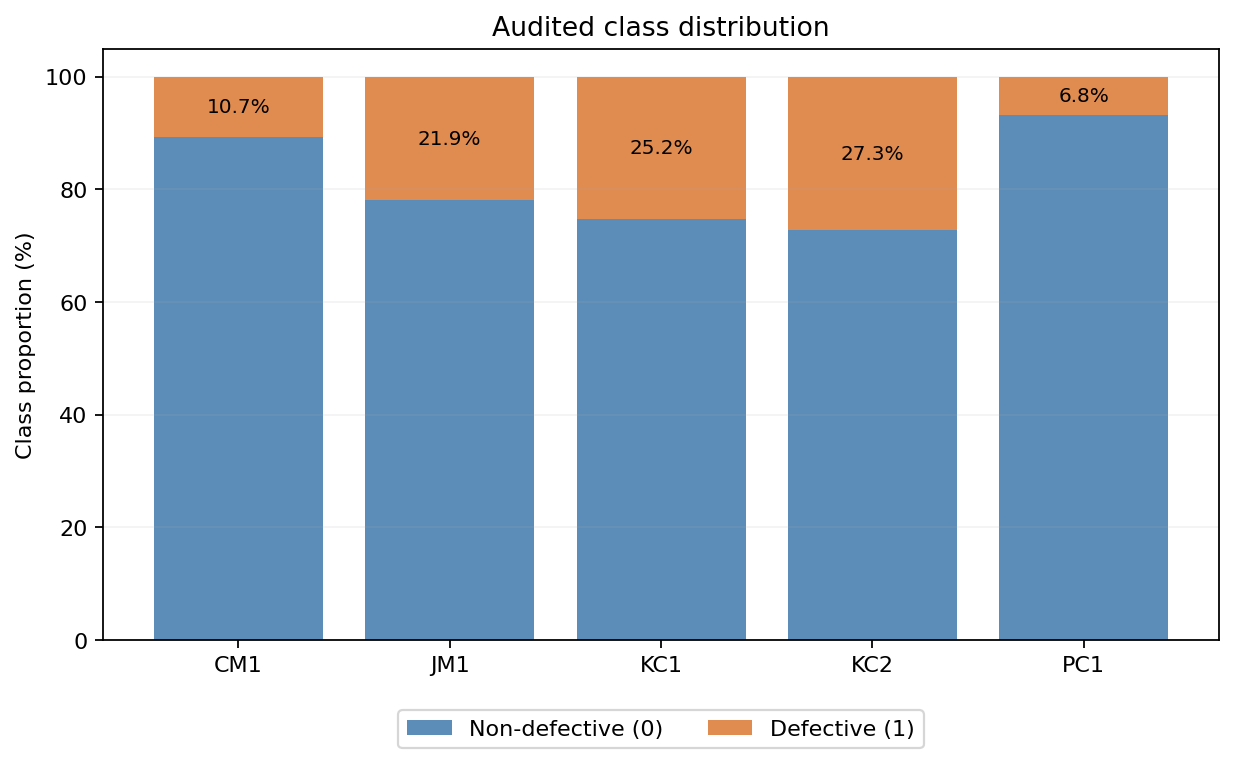

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.8))
positions = np.arange(len(dataset_summary))
prevalence = 100 * dataset_summary["Defect prevalence"].to_numpy()
ax.bar(positions, 100 - prevalence, label="Non-defective (0)", color="#5c8cb8")
ax.bar(
    positions, prevalence, bottom=100 - prevalence,
    label="Defective (1)", color="#e08b50",
)
for position, proportion in zip(positions, prevalence):
    ax.text(
        position, 100 - proportion / 2, f"{proportion:.1f}%",
        ha="center", va="center", fontsize=9,
    )
ax.set_xticks(positions, dataset_summary["Dataset"])
ax.set(ylabel="Class proportion (%)", ylim=(0, 105), title="Audited class distribution")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.grid(axis="y", alpha=0.15)
plt.show()

## 3. Estimators and Preprocessing

In [ ]:
def make_classifier(model_name, seed):
    """Instantiate an ensemble classifier using the fixed configuration."""
    parameters = {"n_estimators": N_ESTIMATORS, "random_state": seed}
    if model_name == "Random Forest":
        return RandomForestClassifier(**parameters, n_jobs=-1)
    if model_name == "Extra Trees":
        return ExtraTreesClassifier(**parameters, n_jobs=-1)
    if model_name == "AdaBoost":
        return AdaBoostClassifier(**parameters)
    if model_name == "Gradient Boosting":
        return GradientBoostingClassifier(**parameters)
    raise ValueError(f"Unknown classifier: {model_name}")


def make_pipeline(model_name, scenario, seed):
    """Construct preprocessing, optional oversampling, and classification."""
    steps = [
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
    ]
    if scenario == "SMOTE":
        sampler = SMOTE(
            sampling_strategy=SAMPLING_STRATEGY,
            k_neighbors=N_NEIGHBORS, random_state=seed,
        )
        steps.append(("sampler", sampler))
    elif scenario == "ADASYN":
        sampler = ADASYN(
            sampling_strategy=SAMPLING_STRATEGY,
            n_neighbors=N_NEIGHBORS, random_state=seed,
        )
        steps.append(("sampler", sampler))
    elif scenario != "Without sampling":
        raise ValueError(f"Unknown sampling scenario: {scenario}")
    steps.append(("classifier", make_classifier(model_name, seed)))
    return Pipeline(steps)


example = make_pipeline("Random Forest", "ADASYN", RANDOM_STATE)
print("Pipeline:", " -> ".join(example.named_steps))
print("Planned fits:", len(DATASETS) * len(MODELS) * len(SCENARIOS) * N_SPLITS * N_REPEATS)

## 4. Repeated Stratified Cross-Validation

In [ ]:
def evaluate_predictions(y_true, y_pred, y_score):
    """Compute binary classification metrics for the defective class."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    n_test = len(y_true)
    metrics = {
        "N_test": n_test,
        "Prevalence_test": float(np.mean(y_true)),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AP": average_precision_score(y_true, y_score),
        "ROC_AUC": roc_auc_score(y_true, y_score),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
        "TP_per_100": 100 * tp / n_test,
        "FP_per_100": 100 * fp / n_test,
    }
    return metrics


def run_cross_validation(data):
    """Evaluate matched splits and retain the selected out-of-fold predictions."""
    fold_records, oof_records = [], []
    for dataset_name, (X, y) in data.items():
        started = perf_counter()
        splitter = RepeatedStratifiedKFold(
            n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE,
        )
        for split_number, (train_index, test_index) in enumerate(splitter.split(X, y)):
            repeat, fold = divmod(split_number, N_SPLITS)
            repeat, fold = repeat + 1, fold + 1
            seed = RANDOM_STATE + repeat - 1
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]
            if y_train.value_counts().min() <= N_NEIGHBORS:
                raise ValueError(
                    f"{dataset_name}, repeat {repeat}, fold {fold}: "
                    f"insufficient minority observations for {N_NEIGHBORS} neighbours."
                )

            for model_name in MODELS:
                for scenario in SCENARIOS:
                    pipeline = make_pipeline(model_name, scenario, seed)
                    try:
                        fit_started = perf_counter()
                        pipeline.fit(X_train, y_train)
                        fit_seconds = perf_counter() - fit_started
                        predict_started = perf_counter()
                        y_score = pipeline.predict_proba(X_test)[:, 1]
                        y_pred = (y_score >= DECISION_THRESHOLD).astype(int)
                        predict_seconds = perf_counter() - predict_started
                    except Exception as error:
                        raise RuntimeError(
                            f"{dataset_name}, repeat {repeat}, fold {fold}, "
                            f"{model_name}, {scenario}: fit or prediction failed."
                        ) from error

                    metrics = evaluate_predictions(y_test, y_pred, y_score)
                    fold_records.append({
                        "Dataset": dataset_name, "Model": model_name,
                        "Scenario": scenario, "Repeat": repeat, "Fold": fold,
                        **metrics,
                        "Fit_seconds": fit_seconds, "Predict_seconds": predict_seconds,
                    })
                    if (
                        dataset_name == ILLUSTRATION_DATASET
                        and model_name == ILLUSTRATION_MODEL and repeat == 1
                    ):
                        predictions = pd.DataFrame({
                            "Scenario": scenario, "Index": test_index,
                            "y_true": y_test.to_numpy(), "y_pred": y_pred,
                            "y_score": y_score,
                        })
                        oof_records.extend(predictions.to_dict("records"))
        print(f"{dataset_name}: cross-validation completed in {perf_counter() - started:.1f}s")
    return pd.DataFrame(fold_records), pd.DataFrame(oof_records)

In [ ]:
started = perf_counter()
fold_results, oof_illustration = run_cross_validation(datasets)
print(f"Completed {len(fold_results)} fits in {perf_counter() - started:.1f}s")
show_table(fold_results.head(12).round(4))

,Dataset,Model,Scenario,Rep,Fold,n_test,Prev,Accuracy,Precision,Recall,...,AUC,TN,FP,FN,TP,FPR,TP/100,FP/100,Fit_s,Pred_s
0,CM1,Random Forest,Without sampling,1,1,88,0.1023,0.8750,0.0000,0.0000,...,0.8129,77,2,9,0,0.0253,0.0000,2.2727,0.3819,0.0609
1,CM1,Random Forest,SMOTE,1,1,88,0.1023,0.8068,0.1667,0.2222,...,0.7278,69,10,7,2,0.1266,2.2727,11.3636,3.4419,0.0531
2,CM1,Random Forest,ADASYN,1,1,88,0.1023,0.8295,0.1250,0.1111,...,0.7166,72,7,8,1,0.0886,1.1364,7.9545,0.3415,0.0494
3,CM1,Extra Trees,Without sampling,1,1,88,0.1023,0.8864,0.3333,0.1111,...,0.7363,77,2,8,1,0.0253,1.1364,2.2727,0.2111,0.0485
4,CM1,Extra Trees,SMOTE,1,1,88,0.1023,0.8523,0.1667,0.1111,...,0.7152,74,5,8,1,0.0633,1.1364,5.6818,0.2640,0.0502
5,CM1,Extra Trees,ADASYN,1,1,88,0.1023,0.8409,0.1429,0.1111,...,0.7496,73,6,8,1,0.0759,1.1364,6.8182,0.2788,0.0516
6,CM1,AdaBoost,Without sampling,1,1,88,0.1023,0.8750,0.0000,0.0000,...,0.7546,77,2,9,0,0.0253,0.0000,2.2727,0.3213,0.0254
7,CM1,AdaBoost,SMOTE,1,1,88,0.1023,0.7159,0.1000,0.2222,...,0.7124,61,18,7,2,0.2278,2.2727,20.4545,0.4534,0.0324
8,CM1,AdaBoost,ADASYN,1,1,88,0.1023,0.7386,0.1818,0.4444,...,0.7405,61,18,5,4,0.2278,4.5455,20.4545,0.4222,0.0214
9,CM1,Gradient Boosting,Without sampling,1,1,88,0.1023,0.8636,0.0000,0.0000,...,0.7665,76,3,9,0,0.0380,0.0000,3.4091,0.3540,0.0053


In [ ]:
expected_groups = len(DATASETS) * len(MODELS) * len(SCENARIOS)
expected_folds = N_SPLITS * N_REPEATS
fold_counts = fold_results.groupby(GROUP_COLUMNS).size()
assert len(fold_counts) == expected_groups
assert len(fold_results) == expected_groups * expected_folds
assert fold_counts.eq(expected_folds).all()
assert not fold_results.duplicated(GROUP_COLUMNS + ["Repeat", "Fold"]).any()
assert fold_results[["TN", "FP", "FN", "TP"]].sum(axis=1).eq(fold_results["N_test"]).all()
bounded_metrics = ["Accuracy", "Precision", "Recall", "F1", "AP", "ROC_AUC", "FPR"]
assert fold_results[bounded_metrics].notna().all().all()
assert ((fold_results[bounded_metrics] >= 0) & (fold_results[bounded_metrics] <= 1)).all().all()
assert fold_results.groupby(PAIR_KEYS)["Scenario"].nunique().eq(len(SCENARIOS)).all()

expected_oof = len(datasets[ILLUSTRATION_DATASET][1])
assert set(oof_illustration["Scenario"]) == set(SCENARIOS)
assert oof_illustration.groupby("Scenario")["Index"].nunique().eq(expected_oof).all()
assert not oof_illustration.duplicated(["Scenario", "Index"]).any()
print(f"Validated {expected_groups} configurations with {expected_folds} folds each.")
show_table(
    fold_results.groupby("Dataset")[["N_test", "Prevalence_test"]]
    .agg(["min", "max", "mean"]).round(4)
)

Dataset  n_test_min  n_test_max  n_test_mean  Prev_min  Prev_max  Prev_mean
    CM1          88          88         88.0    0.1023    0.1136     0.1068
    JM1        1746        1747       1746.4    0.2192    0.2198     0.2194
    KC1         234         235        234.4    0.2511    0.2521     0.2517
    KC2          72          73         72.6    0.2639    0.2778     0.2727
    PC1         188         189        188.4    0.0638    0.0691     0.0679

## 5. Performance Summary

In [ ]:
grouped_results = fold_results.groupby(GROUP_COLUMNS, as_index=False)[METRIC_COLUMNS]
per_dataset = grouped_results.mean()
per_dataset_sd = grouped_results.std().rename(
    columns={metric: f"{metric}_fold_sd" for metric in METRIC_COLUMNS}
)
overall = per_dataset.groupby(["Model", "Scenario"], as_index=False)[METRIC_COLUMNS].mean()
show_table(per_dataset.round(4))
show_table(overall.sort_values(["AP", "F1"], ascending=False).round(4))

,Dataset,Model,Scenario,F1,AP,Recall,Precision,AUC,FPR,TP/100,FP/100,Fit_s
0,CM1,AdaBoost,ADASYN,0.2752,0.2366,0.4396,0.2049,0.7145,0.1959,4.6818,17.5000,0.3577
1,CM1,AdaBoost,SMOTE,0.2698,0.2373,0.4209,0.2030,0.7143,0.1939,4.5000,17.3182,0.3717
2,CM1,AdaBoost,Without sampling,0.0895,0.2572,0.0644,0.1638,0.7069,0.0305,0.6818,2.7273,0.2529
3,CM1,Extra Trees,ADASYN,0.1787,0.2220,0.1787,0.1901,0.7194,0.0962,1.9091,8.5909,0.2038
4,CM1,Extra Trees,SMOTE,0.1770,0.2210,0.1796,0.1811,0.7172,0.0992,1.9091,8.8636,0.1991
5,CM1,Extra Trees,Without sampling,0.0400,0.2165,0.0267,0.1013,0.7200,0.0203,0.2727,1.8182,0.1666
6,CM1,Gradient Boosting,ADASYN,0.1939,0.2191,0.2333,0.1781,0.6755,0.1252,2.5000,11.1818,0.4644
7,CM1,Gradient Boosting,SMOTE,0.1849,0.2179,0.2253,0.1648,0.6743,0.1303,2.4091,11.6364,0.4645
8,CM1,Gradient Boosting,Without sampling,0.1483,0.2362,0.1204,0.2186,0.6889,0.0371,1.2727,3.3182,0.2747
9,CM1,Random Forest,ADASYN,0.1775,0.2142,0.1991,0.1675,0.7104,0.1211,2.1364,10.8182,0.2689


,Model,Scenario,F1,AP,Recall,Precision,AUC,FPR,TP/100,FP/100,Fit_s
11,Random Forest,Without sampling,0.3210,0.4434,0.2561,0.4776,0.7614,0.0554,5.7533,4.2251,0.2267
5,Extra Trees,Without sampling,0.3226,0.4415,0.2577,0.4867,0.7646,0.0596,5.7665,4.5402,0.1633
4,Extra Trees,SMOTE,0.4054,0.4377,0.3987,0.4204,0.7647,0.1194,8.0869,9.3938,0.2065
10,Random Forest,SMOTE,0.4008,0.4358,0.4053,0.4063,0.7638,0.1290,8.2246,10.1751,0.3069
3,Extra Trees,ADASYN,0.4073,0.4347,0.4079,0.4166,0.7631,0.1252,8.2688,9.8230,0.2055
8,Gradient Boosting,Without sampling,0.3145,0.4302,0.2510,0.4853,0.7461,0.0580,5.3277,4.4780,0.5797
9,Random Forest,ADASYN,0.3999,0.4249,0.4151,0.3962,0.7619,0.1392,8.3987,10.9493,0.2929
7,Gradient Boosting,SMOTE,0.3887,0.4233,0.4071,0.3828,0.7466,0.1396,8.0794,11.0969,1.1179
2,AdaBoost,Without sampling,0.2719,0.4187,0.2105,0.4945,0.7457,0.0457,4.6532,3.5393,0.3541
1,AdaBoost,SMOTE,0.4184,0.4164,0.5484,0.3475,0.7515,0.2199,10.6077,17.5743,0.5959


In [ ]:
performance_table = overall[
    ["Model", "Scenario", "F1", "AP", "Recall", "Precision", "ROC_AUC", "FPR"]
].sort_values(["Model", "Scenario"])
show_table(performance_table.round(4))

f1_table = per_dataset.pivot(index=["Dataset", "Model"], columns="Scenario", values="F1")
ap_table = per_dataset.pivot(index=["Dataset", "Model"], columns="Scenario", values="AP")
print("F1 by dataset and classifier")
show_table(f1_table.reindex(columns=SCENARIOS).round(4))
print("Average precision by dataset and classifier")
show_table(ap_table.reindex(columns=SCENARIOS).round(4))

,Model,Scenario,F1,AP,Recall,Precision,AUC,FPR
0,AdaBoost,ADASYN,0.415,0.403,0.560,0.339,0.747,0.233
1,AdaBoost,SMOTE,0.418,0.416,0.548,0.348,0.751,0.220
2,AdaBoost,Without sampling,0.272,0.419,0.210,0.495,0.746,0.046
3,Extra Trees,ADASYN,0.407,0.435,0.408,0.417,0.763,0.125
4,Extra Trees,SMOTE,0.405,0.438,0.399,0.420,0.765,0.119
5,Extra Trees,Without sampling,0.323,0.441,0.258,0.487,0.765,0.060
6,Gradient Boosting,ADASYN,0.389,0.414,0.413,0.379,0.745,0.146
7,Gradient Boosting,SMOTE,0.389,0.423,0.407,0.383,0.747,0.140
8,Gradient Boosting,Without sampling,0.314,0.430,0.251,0.485,0.746,0.058
9,Random Forest,ADASYN,0.400,0.425,0.415,0.396,0.762,0.139


Scenario,Dataset,Model,Baseline,SMOTE,ADASYN
0,CM1,AdaBoost,0.090,0.270,0.275
1,CM1,Extra Trees,0.040,0.177,0.179
2,CM1,Gradient Boosting,0.148,0.185,0.194
3,CM1,Random Forest,0.014,0.172,0.178
4,JM1,AdaBoost,0.163,0.450,0.446
5,JM1,Extra Trees,0.320,0.418,0.421
6,JM1,Gradient Boosting,0.244,0.415,0.411
7,JM1,Random Forest,0.315,0.417,0.414
8,KC1,AdaBoost,0.308,0.474,0.466
9,KC1,Extra Trees,0.419,0.472,0.468


Scenario,Dataset,Model,Baseline,SMOTE,ADASYN
0,CM1,AdaBoost,0.257,0.237,0.237
1,CM1,Extra Trees,0.217,0.221,0.222
2,CM1,Gradient Boosting,0.236,0.218,0.219
3,CM1,Random Forest,0.232,0.224,0.214
4,JM1,AdaBoost,0.411,0.413,0.404
5,JM1,Extra Trees,0.425,0.422,0.421
6,JM1,Gradient Boosting,0.429,0.426,0.421
7,JM1,Random Forest,0.425,0.429,0.425
8,KC1,AdaBoost,0.449,0.473,0.451
9,KC1,Extra Trees,0.504,0.502,0.495


## 6. Paired Effects and Detection Trade-Offs

In [ ]:
paired_frames = []
for comparison, left_scenario, right_scenario in COMPARISONS:
    left = fold_results.loc[
        fold_results["Scenario"] == left_scenario, PAIR_KEYS + PAIRED_METRICS,
    ]
    right = fold_results.loc[
        fold_results["Scenario"] == right_scenario, PAIR_KEYS + PAIRED_METRICS,
    ]
    matched = left.merge(
        right, on=PAIR_KEYS, suffixes=("_left", "_right"), validate="one_to_one",
    )
    assert len(matched) == len(DATASETS) * len(MODELS) * N_SPLITS * N_REPEATS
    effects = matched[PAIR_KEYS].copy()
    effects["Comparison"] = comparison
    for metric in PAIRED_METRICS:
        effects[f"Delta_{metric}"] = matched[f"{metric}_left"] - matched[f"{metric}_right"]
    paired_frames.append(effects)

paired_folds = pd.concat(paired_frames, ignore_index=True)
effect_groups = ["Dataset", "Model", "Comparison"]
delta_columns = [f"Delta_{metric}" for metric in PAIRED_METRICS]
paired_dataset = paired_folds.groupby(effect_groups, as_index=False)[delta_columns].mean()
improved_folds = (
    paired_folds.assign(improved=paired_folds["Delta_F1"] > 0)
    .groupby(effect_groups, as_index=False)
    .agg(F1_folds=("improved", "sum"))
)
paired_dataset = paired_dataset.merge(improved_folds, on=effect_groups, validate="one_to_one")
show_table(paired_dataset.round(4))

,Dataset,Model,Comparison,dF1,dAP,dRecall,dPrecision,dAUC,dFPR,dTP100,dFP100,dTP,dFP,dFN,F1_folds
0,CM1,AdaBoost,ADASYN vs SMOTE,0.0054,-0.0008,0.0187,0.0019,0.0002,0.0020,0.1818,0.1818,0.16,0.16,-0.16,14
1,CM1,AdaBoost,ADASYN vs baseline,0.1857,-0.0206,0.3751,0.0411,0.0075,0.1654,4.0000,14.7727,3.52,13.00,-3.52,23
2,CM1,AdaBoost,SMOTE vs baseline,0.1803,-0.0199,0.3564,0.0392,0.0073,0.1634,3.8182,14.5909,3.36,12.84,-3.36,23
3,CM1,Extra Trees,ADASYN vs SMOTE,0.0017,0.0010,-0.0009,0.0091,0.0021,-0.0031,0.0000,-0.2727,0.00,-0.24,0.00,11
4,CM1,Extra Trees,ADASYN vs baseline,0.1387,0.0055,0.1520,0.0888,-0.0006,0.0758,1.6364,6.7727,1.44,5.96,-1.44,20
5,CM1,Extra Trees,SMOTE vs baseline,0.1370,0.0044,0.1529,0.0797,-0.0027,0.0789,1.6364,7.0455,1.44,6.20,-1.44,22
6,CM1,Gradient Boosting,ADASYN vs SMOTE,0.0090,0.0012,0.0080,0.0133,0.0012,-0.0051,0.0909,-0.4545,0.08,-0.40,-0.08,14
7,CM1,Gradient Boosting,ADASYN vs baseline,0.0457,-0.0171,0.1129,-0.0406,-0.0134,0.0880,1.2273,7.8636,1.08,6.92,-1.08,14
8,CM1,Gradient Boosting,SMOTE vs baseline,0.0366,-0.0183,0.1049,-0.0539,-0.0146,0.0931,1.1364,8.3182,1.00,7.32,-1.00,13
9,CM1,Random Forest,ADASYN vs SMOTE,0.0058,-0.0099,0.0124,-0.0015,-0.0005,0.0076,0.1364,0.6818,0.12,0.60,-0.12,9


In [ ]:
consistency = paired_dataset.groupby(["Model", "Comparison"]).agg(
    n=("Dataset", "size"),
    F1_up=("Delta_F1", lambda values: int((values > 0).sum())),
    AP_up=("Delta_AP", lambda values: int((values > 0).sum())),
    dF1=("Delta_F1", "mean"),
    dF1_min=("Delta_F1", "min"),
    dF1_max=("Delta_F1", "max"),
    dAP=("Delta_AP", "mean"),
    dRecall=("Delta_Recall", "mean"),
    dTP100=("Delta_TP_per_100", "mean"),
    dFP100=("Delta_FP_per_100", "mean"),
).reset_index()
tradeoff = paired_dataset.loc[
    paired_dataset["Comparison"] == "ADASYN vs baseline",
    ["Dataset", "Model", "Delta_F1", "Delta_AP", "Delta_Recall",
     "Delta_TP_per_100", "Delta_FP_per_100", "Delta_FN"],
]
show_table(consistency.round(4))
show_table(tradeoff.sort_values(["Dataset", "Model"]).round(4))

,Model,Comparison,n,F1_up,AP_up,dF1,dF1_min,dF1_max,dAP,dRecall,dTP100,dFP100
0,AdaBoost,ADASYN vs SMOTE,5,2,0,-0.0029,-0.0157,0.0070,-0.0137,0.0115,0.2716,0.9974
1,AdaBoost,ADASYN vs baseline,5,5,1,0.1436,0.0277,0.2832,-0.0160,0.3494,6.2261,15.0324
2,AdaBoost,SMOTE vs baseline,5,5,3,0.1465,0.0207,0.2873,-0.0023,0.3379,5.9545,14.0350
3,Extra Trees,ADASYN vs SMOTE,5,3,2,0.0019,-0.0039,0.0098,-0.0030,0.0091,0.1819,0.4293
4,Extra Trees,ADASYN vs baseline,5,5,1,0.0847,0.0234,0.1387,-0.0068,0.1502,2.5023,5.2829
5,Extra Trees,SMOTE vs baseline,5,5,1,0.0827,0.0245,0.1370,-0.0038,0.1410,2.3203,4.8536
6,Gradient Boosting,ADASYN vs SMOTE,5,3,1,0.0004,-0.0137,0.0090,-0.0089,0.0062,0.2031,0.4702
7,Gradient Boosting,ADASYN vs baseline,5,5,0,0.0746,0.0134,0.1670,-0.0157,0.1623,2.9548,7.0892
8,Gradient Boosting,SMOTE vs baseline,5,5,1,0.0742,0.0063,0.1703,-0.0068,0.1561,2.7517,6.6189
9,Random Forest,ADASYN vs SMOTE,5,2,0,-0.0009,-0.0063,0.0058,-0.0109,0.0098,0.1741,0.7742


,Dataset,Model,dF1,dAP,dRecall,dTP100,dFP100,dFN
1,CM1,AdaBoost,0.1857,-0.0206,0.3751,4.0000,14.7727,-3.52
4,CM1,Extra Trees,0.1387,0.0055,0.1520,1.6364,6.7727,-1.44
7,CM1,Gradient Boosting,0.0457,-0.0171,0.1129,1.2273,7.8636,-1.08
10,CM1,Random Forest,0.1636,-0.0182,0.1907,2.0455,9.2727,-1.80
13,JM1,AdaBoost,0.2832,-0.0078,0.4607,10.1099,19.1846,-176.56
16,JM1,Extra Trees,0.1003,-0.0037,0.1610,3.5318,5.7581,-61.68
19,JM1,Gradient Boosting,0.1670,-0.0079,0.2455,5.3871,9.4869,-94.08
22,JM1,Random Forest,0.0996,-0.0004,0.1538,3.3738,5.4557,-58.92
25,KC1,AdaBoost,0.1583,0.0024,0.3756,9.4531,19.4690,-22.16
28,KC1,Extra Trees,0.0487,-0.0094,0.1098,2.7639,4.8797,-6.48


In [ ]:
effect_table = consistency.loc[
    consistency["Comparison"].isin(PRIMARY_COMPARISONS),
    ["Model", "Comparison", "F1_up", "dF1", "dAP", "dRecall", "dTP100", "dFP100"],
]
show_table(effect_table.round(4))

,Model,Comparison,F1_up,dF1,dAP,dRecall,dTP100,dFP100
0,AdaBoost,ADASYN vs SMOTE,2,-0.003,-0.014,0.011,0.272,0.997
1,AdaBoost,ADASYN vs baseline,5,0.144,-0.016,0.349,6.226,15.032
3,Extra Trees,ADASYN vs SMOTE,3,0.002,-0.003,0.009,0.182,0.429
4,Extra Trees,ADASYN vs baseline,5,0.085,-0.007,0.150,2.502,5.283
6,Gradient Boosting,ADASYN vs SMOTE,3,0.000,-0.009,0.006,0.203,0.470
7,Gradient Boosting,ADASYN vs baseline,5,0.075,-0.016,0.162,2.955,7.089
9,Random Forest,ADASYN vs SMOTE,2,-0.001,-0.011,0.010,0.174,0.774
10,Random Forest,ADASYN vs baseline,4,0.079,-0.018,0.159,2.645,6.724


## 7. Performance and Effect Visualisation

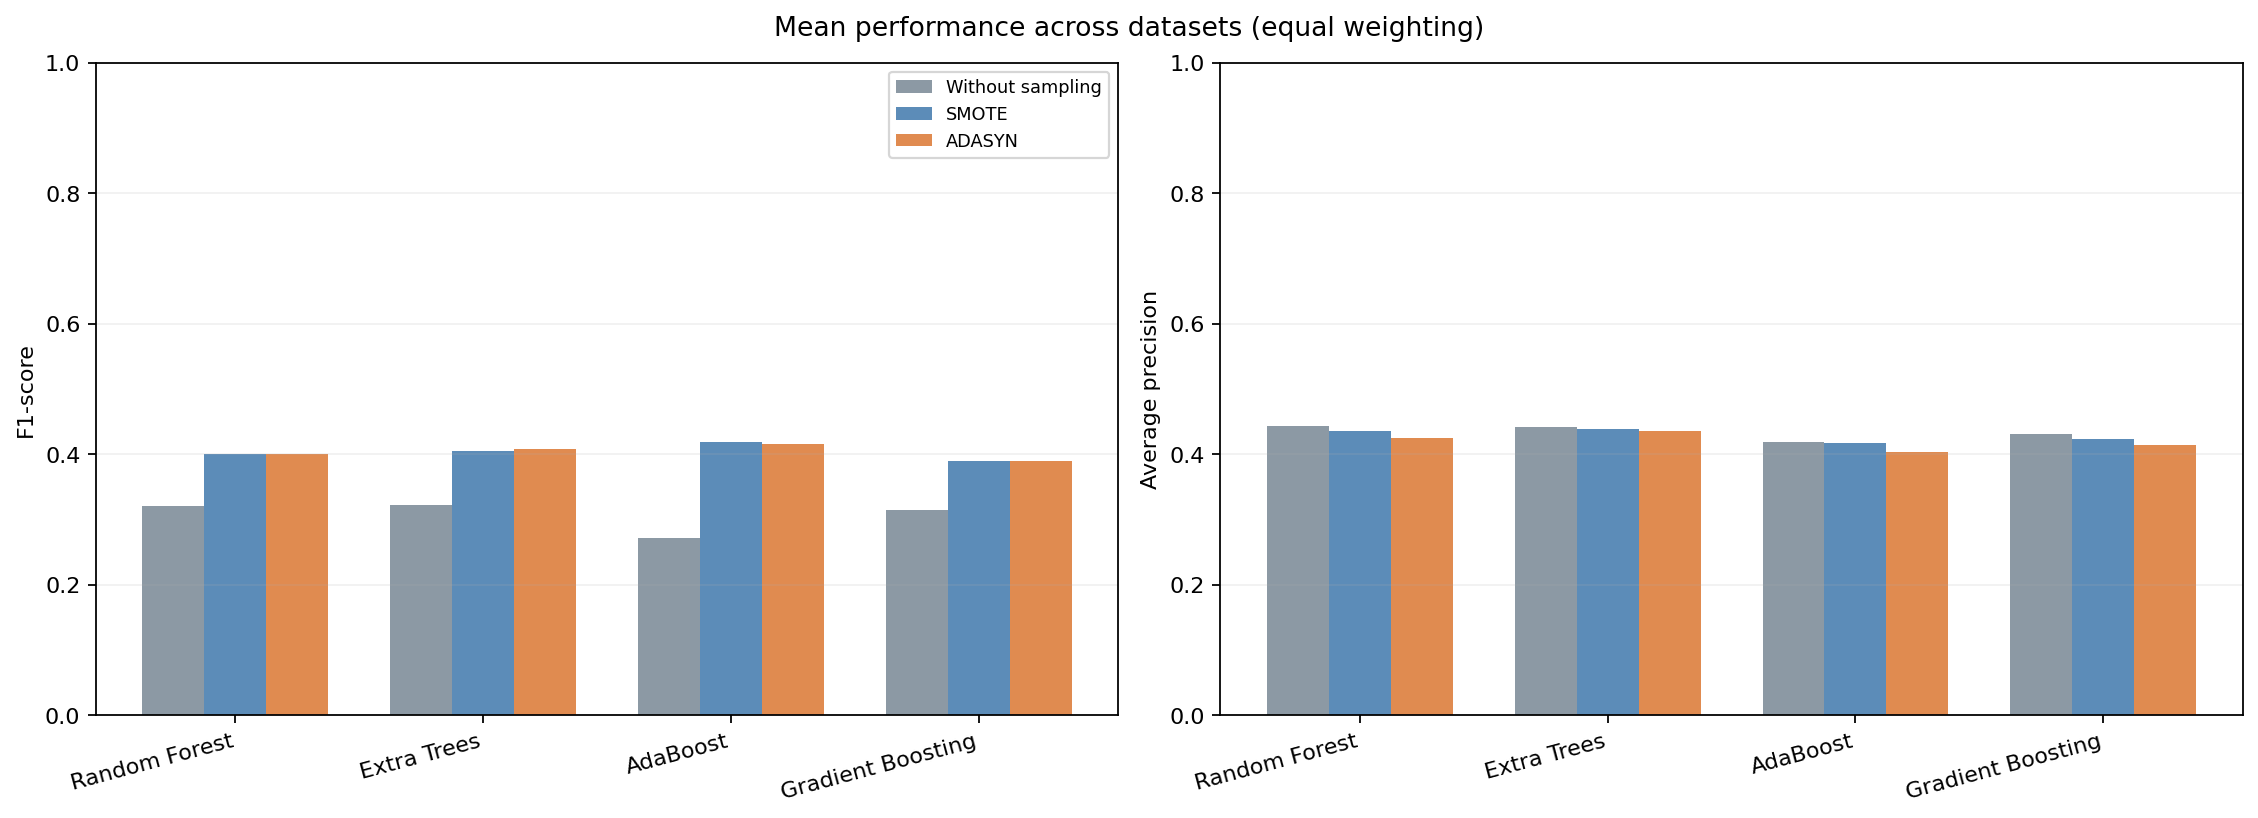

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
positions = np.arange(len(MODELS))
width = 0.25
for ax, metric, label in zip(axes, ("F1", "AP"), ("F1-score", "Average precision")):
    for offset, scenario in enumerate(SCENARIOS):
        values = (
            overall.loc[overall["Scenario"] == scenario]
            .set_index("Model").reindex(MODELS)[metric].to_numpy()
        )
        ax.bar(
            positions + (offset - 1) * width, values, width,
            label=scenario, color=PALETTE[scenario],
        )
    ax.set_xticks(positions, MODELS, rotation=15, ha="right")
    ax.set(ylabel=label, ylim=(0, 1))
    ax.grid(axis="y", alpha=0.18)
axes[0].legend(fontsize=8)
fig.suptitle("Mean performance across datasets (equal weighting)")
plt.show()

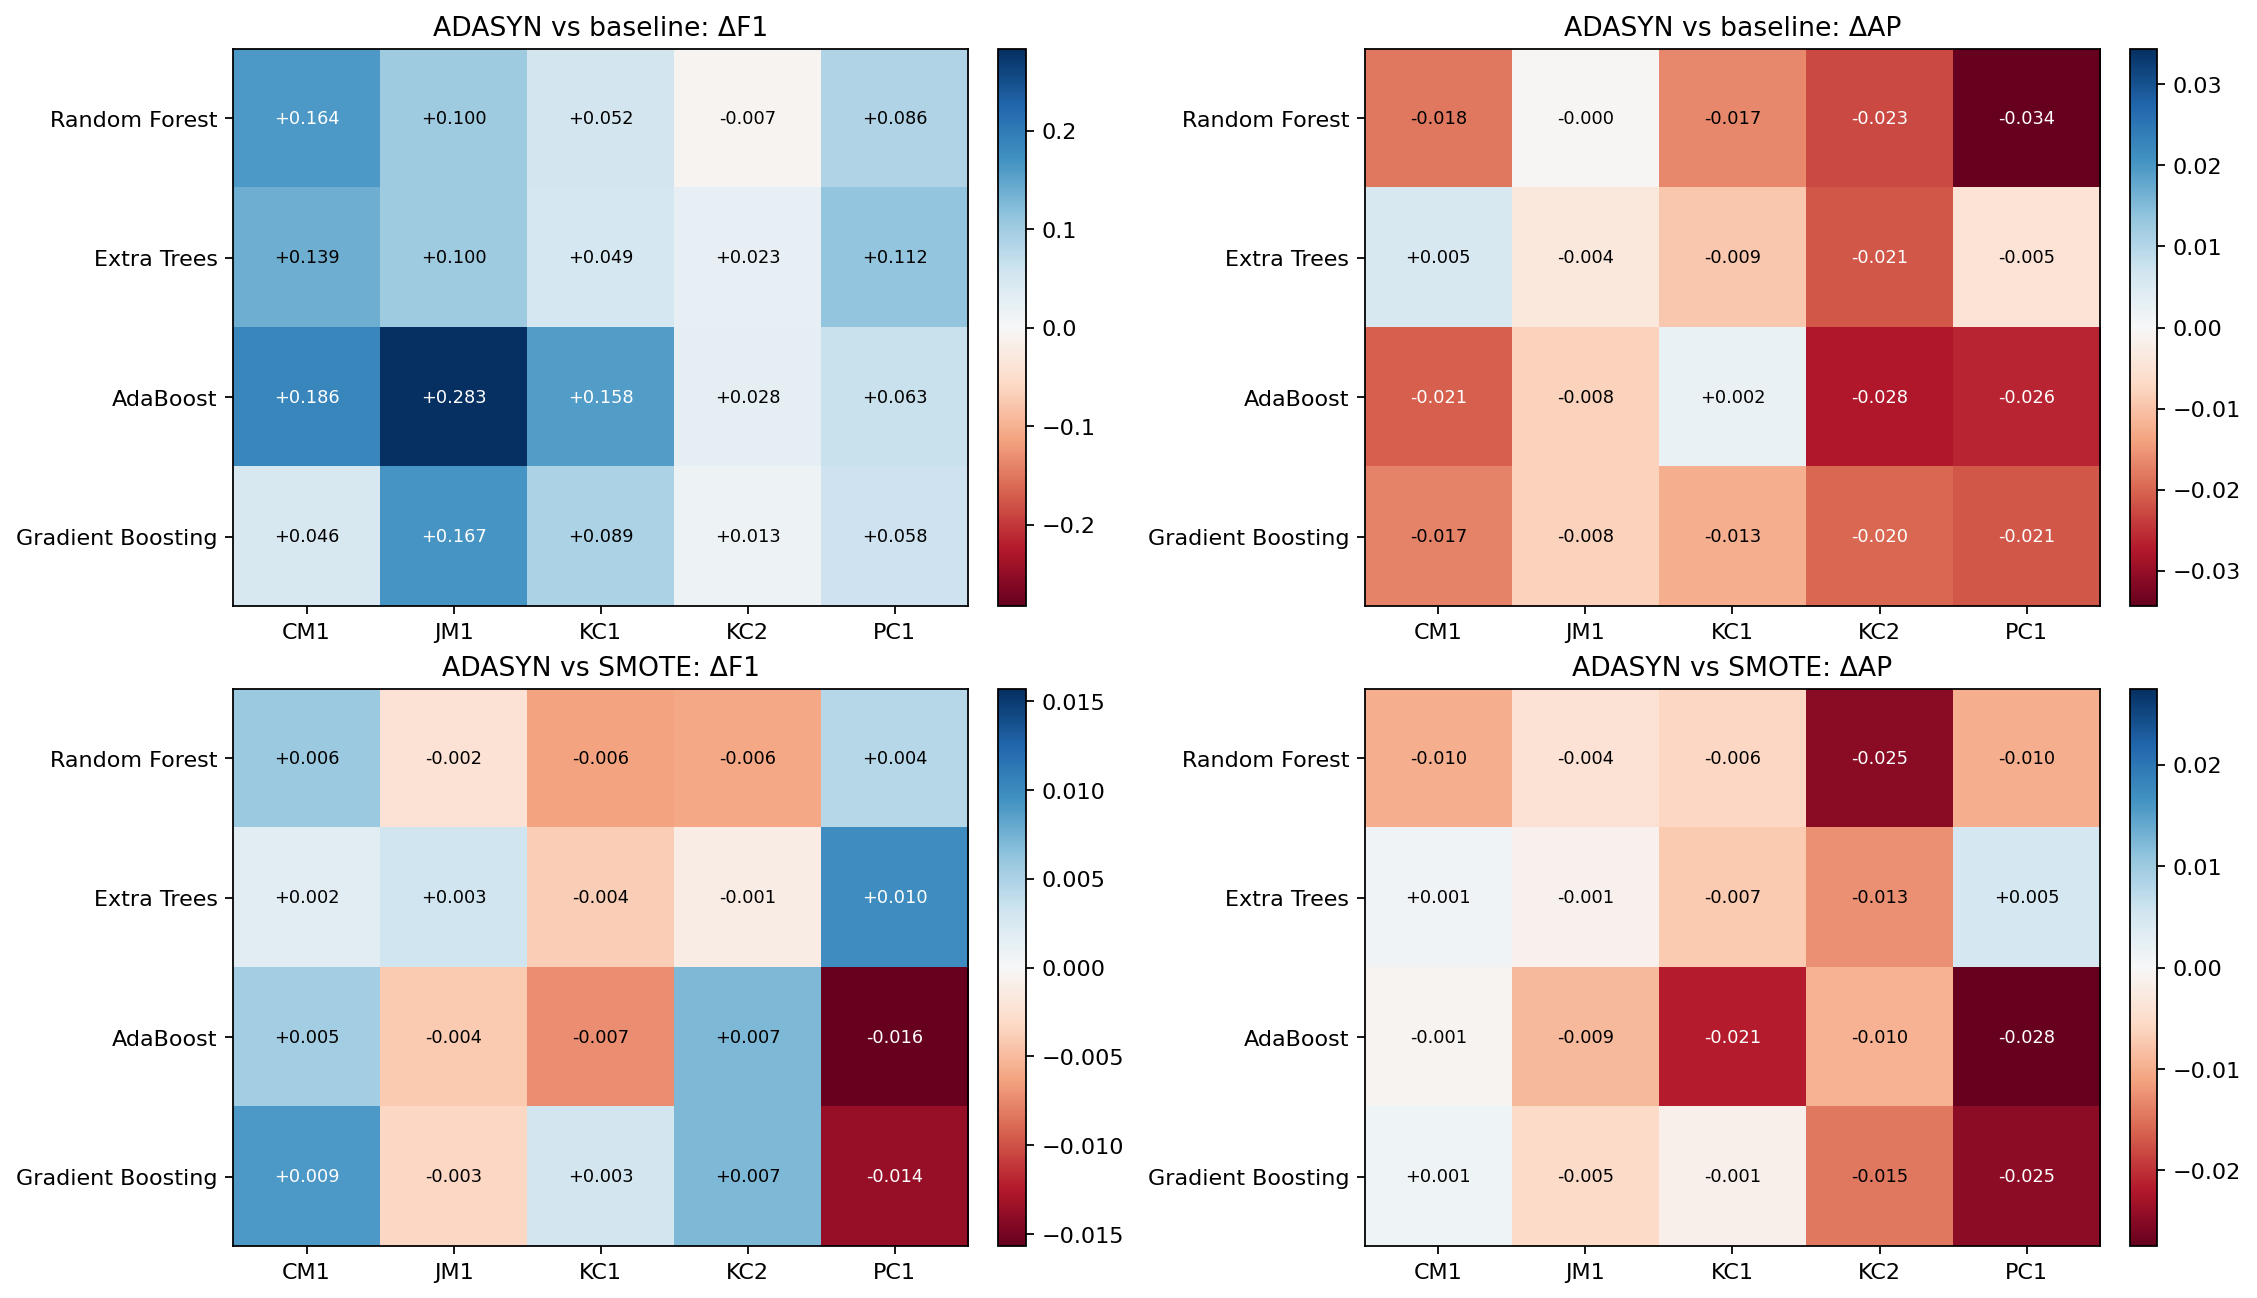

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for row, comparison in enumerate(PRIMARY_COMPARISONS):
    current = paired_dataset.loc[paired_dataset["Comparison"] == comparison]
    for column, metric in enumerate(PRIMARY_METRICS):
        matrix = current.pivot(index="Model", columns="Dataset", values=f"Delta_{metric}")
        matrix = matrix.reindex(index=MODELS, columns=list(DATASETS))
        ax = axes[row, column]
        scale = max(float(np.abs(matrix.to_numpy()).max()), 0.01)
        image = ax.imshow(matrix, cmap="RdBu", vmin=-scale, vmax=scale, aspect="auto")
        ax.set_xticks(range(len(DATASETS)), list(DATASETS))
        ax.set_yticks(range(len(MODELS)), MODELS)
        ax.set_title(f"{comparison}: Δ{metric}")
        for i in range(len(MODELS)):
            for j in range(len(DATASETS)):
                value = matrix.iloc[i, j]
                ax.text(
                    j, i, f"{value:+.3f}", ha="center", va="center",
                    color="white" if abs(value) > scale * 0.55 else "black", fontsize=8,
                )
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.show()

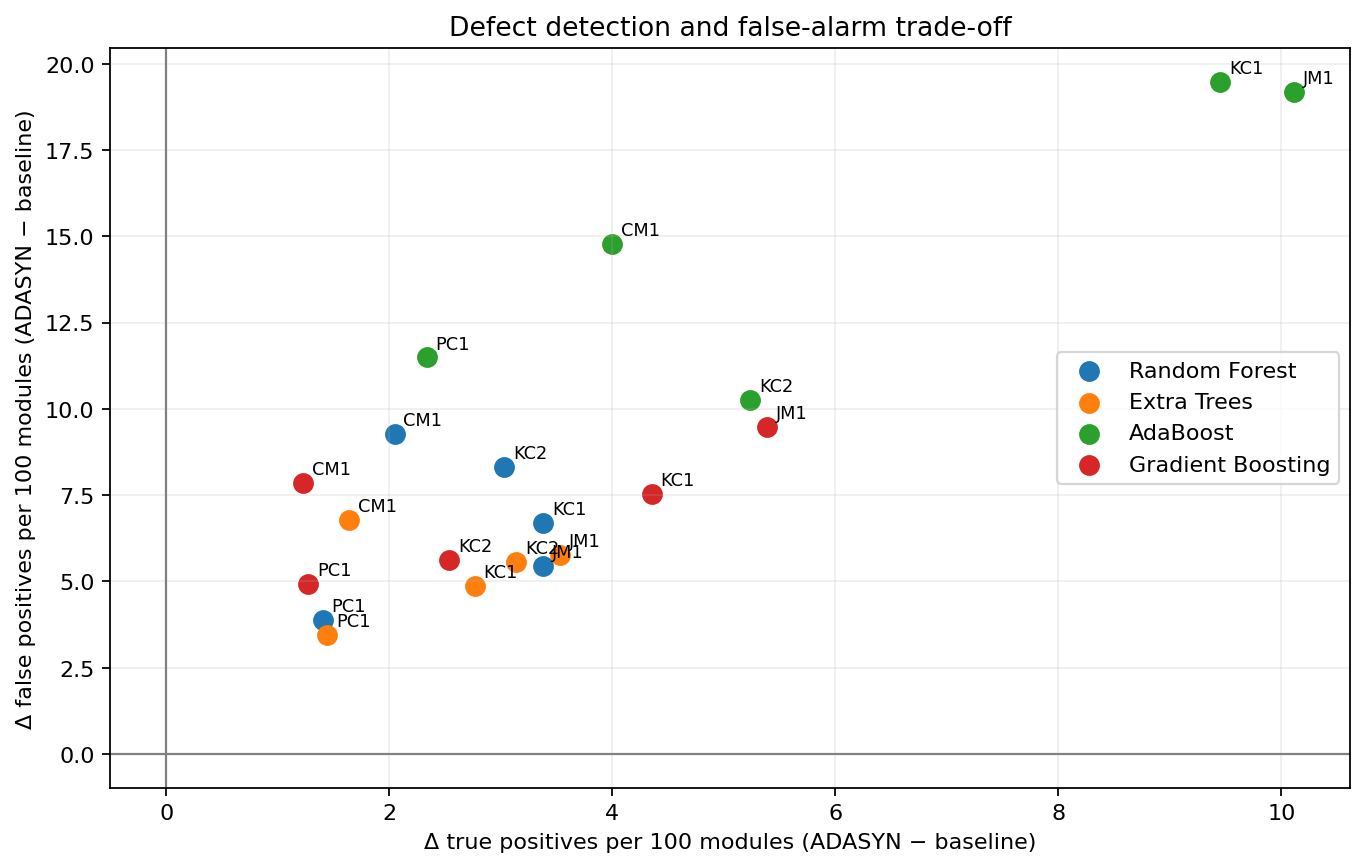

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.get_cmap("tab10")
for index, model_name in enumerate(MODELS):
    current = tradeoff.loc[tradeoff["Model"] == model_name]
    ax.scatter(
        current["Delta_TP_per_100"], current["Delta_FP_per_100"],
        color=colors(index), label=model_name, s=70,
    )
    for record in current.itertuples(index=False):
        ax.annotate(
            record.Dataset, (record.Delta_TP_per_100, record.Delta_FP_per_100),
            xytext=(4, 4), textcoords="offset points", fontsize=8,
        )
ax.axhline(0, color="gray", linewidth=1)
ax.axvline(0, color="gray", linewidth=1)
ax.set(
    xlabel="Δ true positives per 100 modules (ADASYN − baseline)",
    ylabel="Δ false positives per 100 modules (ADASYN − baseline)",
    title="Defect detection and false-alarm trade-off",
)
ax.legend(loc="best")
ax.grid(alpha=0.2)
plt.show()

## 8. Out-of-Fold Diagnostics

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
for scenario in SCENARIOS:
    current = oof_illustration.loc[oof_illustration["Scenario"] == scenario]
    precision, recall, _ = precision_recall_curve(current["y_true"], current["y_score"])
    ap = average_precision_score(current["y_true"], current["y_score"])
    ax.plot(recall, precision, linewidth=1.8, label=f"{scenario} (AP={ap:.3f})")
ax.axhline(
    datasets[ILLUSTRATION_DATASET][1].mean(), linestyle="--",
    color="gray", linewidth=1, label="Defect prevalence",
)
ax.set(
    xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision",
    title=f"Out-of-fold PR curve: {ILLUSTRATION_DATASET}, {ILLUSTRATION_MODEL}, repeat 1",
)
ax.legend(loc="best")
ax.grid(alpha=0.18)
plt.show()

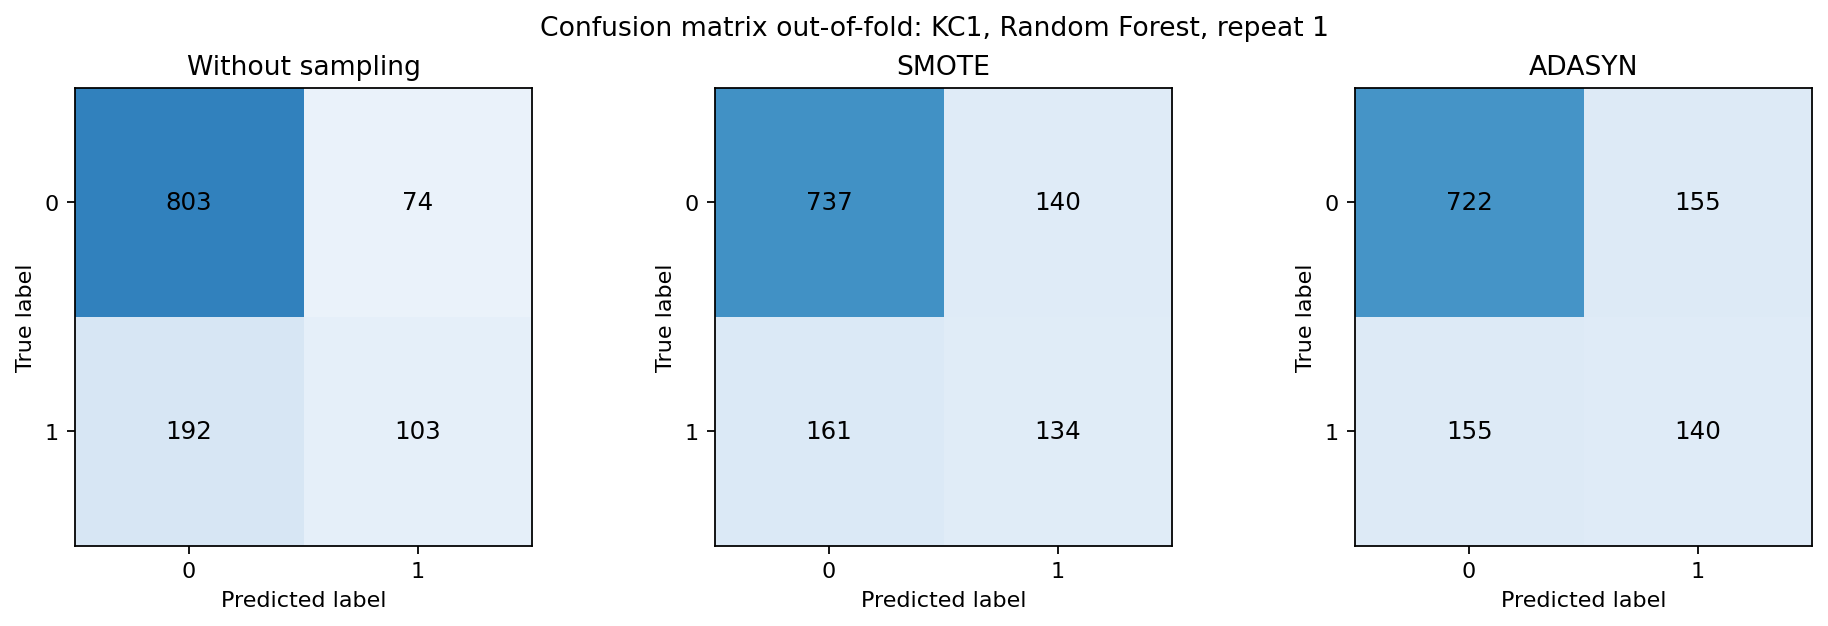

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)
for ax, scenario in zip(axes, SCENARIOS):
    current = oof_illustration.loc[oof_illustration["Scenario"] == scenario]
    matrix = confusion_matrix(current["y_true"], current["y_pred"], labels=[0, 1])
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(len(current), 1))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=11)
    ax.set_xticks([0, 1], ["0", "1"])
    ax.set_yticks([0, 1], ["0", "1"])
    ax.set(xlabel="Predicted label", ylabel="True label", title=scenario)
fig.suptitle(
    f"Out-of-fold confusion matrices: {ILLUSTRATION_DATASET}, {ILLUSTRATION_MODEL}, repeat 1"
)
plt.show()

## 9. Dataset-Level Inference

In [ ]:
def percentile_interval(values, rng, replications=BOOTSTRAP_REPLICATIONS):
    """Percentile bootstrap confidence interval for a dataset-level mean."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size < 2:
        return np.nan, np.nan
    indices = rng.integers(0, values.size, size=(replications, values.size))
    bootstrap_means = values[indices].mean(axis=1)
    return tuple(np.quantile(bootstrap_means, [ALPHA / 2, 1 - ALPHA / 2]))


def holm_adjust(p_values):
    """Apply Holm's step-down correction, retaining missing p-values."""
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan)
    valid = np.flatnonzero(np.isfinite(p_values))
    order = valid[np.argsort(p_values[valid])]
    running_max = 0.0
    for rank, index in enumerate(order):
        candidate = min(1.0, (len(order) - rank) * p_values[index])
        running_max = max(running_max, candidate)
        adjusted[index] = running_max
    return adjusted

In [ ]:
bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED)
uncertainty_records = []
for comparison in PRIMARY_COMPARISONS:
    # Fixed classifier ordering also fixes the bootstrap random-number sequence.
    for model_name in sorted(paired_dataset["Model"].unique()):
        current = paired_dataset.loc[
            (paired_dataset["Comparison"] == comparison)
            & (paired_dataset["Model"] == model_name)
        ]
        for metric in PRIMARY_METRICS:
            values = current[f"Delta_{metric}"].dropna().to_numpy(dtype=float)
            low, high = percentile_interval(values, bootstrap_rng)
            nonzero = values[values != 0]
            sign_p = (
                binomtest(int((nonzero > 0).sum()), n=len(nonzero), p=0.5).pvalue
                if len(nonzero) else np.nan
            )
            uncertainty_records.append({
                "Comparison": comparison, "Model": model_name, "Metric": metric,
                "n": len(values), "n_up": int((values > 0).sum()),
                "Mean": float(values.mean()), "Median": float(np.median(values)),
                "CI_lo": low, "CI_hi": high, "p_sign": sign_p,
            })
uncertainty_by_model = pd.DataFrame(uncertainty_records)
uncertainty_by_model["p_Holm"] = holm_adjust(uncertainty_by_model["p_sign"])
show_table(uncertainty_by_model.round(4))

,Comparison,Model,Metric,n,n_up,Mean,Median,CI_lo,CI_hi,p_sign,p_Holm
0,ADASYN vs baseline,AdaBoost,F1,5,5,0.1436,0.1583,0.0664,0.2197,0.0625,1.0
1,ADASYN vs baseline,AdaBoost,AP,5,1,-0.0160,-0.0206,-0.0256,-0.0054,0.3750,1.0
2,ADASYN vs baseline,Extra Trees,F1,5,5,0.0847,0.1003,0.0462,0.1204,0.0625,1.0
3,ADASYN vs baseline,Extra Trees,AP,5,1,-0.0068,-0.0048,-0.0148,0.0007,0.3750,1.0
4,ADASYN vs baseline,Gradient Boosting,F1,5,5,0.0746,0.0577,0.0351,0.1209,0.0625,1.0
5,ADASYN vs baseline,Gradient Boosting,AP,5,0,-0.0157,-0.0171,-0.0199,-0.0112,0.0625,1.0
6,ADASYN vs baseline,Random Forest,F1,5,4,0.0789,0.0858,0.0286,0.1285,0.3750,1.0
7,ADASYN vs baseline,Random Forest,AP,5,0,-0.0185,-0.0182,-0.0280,-0.0081,0.0625,1.0
8,ADASYN vs SMOTE,AdaBoost,F1,5,2,-0.0029,-0.0041,-0.0100,0.0041,1.0000,1.0
9,ADASYN vs SMOTE,AdaBoost,AP,5,0,-0.0137,-0.0096,-0.0226,-0.0058,0.0625,1.0


In [ ]:
overall_records = []
for comparison in PRIMARY_COMPARISONS:
    current = paired_dataset.loc[paired_dataset["Comparison"] == comparison]
    dataset_names = current["Dataset"].drop_duplicates().to_numpy()
    for metric in PRIMARY_METRICS:
        column = f"Delta_{metric}"
        cluster_means = (
            current.groupby("Dataset", sort=False)[column]
            .mean().reindex(dataset_names).to_numpy(dtype=float)
        )
        low, high = percentile_interval(cluster_means, bootstrap_rng)
        overall_records.append({
            "Comparison": comparison, "Metric": metric,
            "n": len(dataset_names),
            "k": current["Model"].nunique(),
            "Mean": float(current[column].mean()),
            "CI_lo": float(low), "CI_hi": float(high),
        })
overall_clustered_uncertainty = pd.DataFrame(overall_records)
show_table(overall_clustered_uncertainty.round(4))

,Comparison,Metric,n,k,Mean,CI_lo,CI_hi
0,ADASYN vs baseline,F1,5,4,0.0955,0.0513,0.1392
1,ADASYN vs baseline,AP,5,4,-0.0142,-0.0204,-0.0081
2,ADASYN vs SMOTE,F1,5,4,-0.0004,-0.0033,0.0029
3,ADASYN vs SMOTE,AP,5,4,-0.0091,-0.0136,-0.0046


In [ ]:
friedman_records = []
for model_name in sorted(per_dataset["Model"].unique()):
    for metric in PRIMARY_METRICS:
        matrix = (
            per_dataset.loc[per_dataset["Model"] == model_name]
            .pivot(index="Dataset", columns="Scenario", values=metric)
            .reindex(columns=SCENARIOS).dropna()
        )
        if len(matrix) < 3:
            statistic, p_value = np.nan, np.nan
        else:
            statistic, p_value = friedmanchisquare(*(matrix[scenario] for scenario in SCENARIOS))
        friedman_records.append({
            "Model": model_name, "Metric": metric, "n": len(matrix),
            "Chi2": statistic, "p": p_value,
        })
friedman_results = pd.DataFrame(friedman_records)
friedman_results["p_Holm"] = holm_adjust(friedman_results["p"])
show_table(friedman_results.round(4))

,Model,Metric,n,Chi2,p,p_Holm
0,AdaBoost,F1,5,7.6,0.0224,0.1790
1,AdaBoost,AP,5,5.2,0.0743,0.2228
2,Extra Trees,F1,5,7.6,0.0224,0.1790
3,Extra Trees,AP,5,2.8,0.2466,0.4932
4,Gradient Boosting,F1,5,7.6,0.0224,0.1790
5,Gradient Boosting,AP,5,6.4,0.0408,0.1790
6,Random Forest,F1,5,2.8,0.2466,0.4932
7,Random Forest,AP,5,7.6,0.0224,0.1790


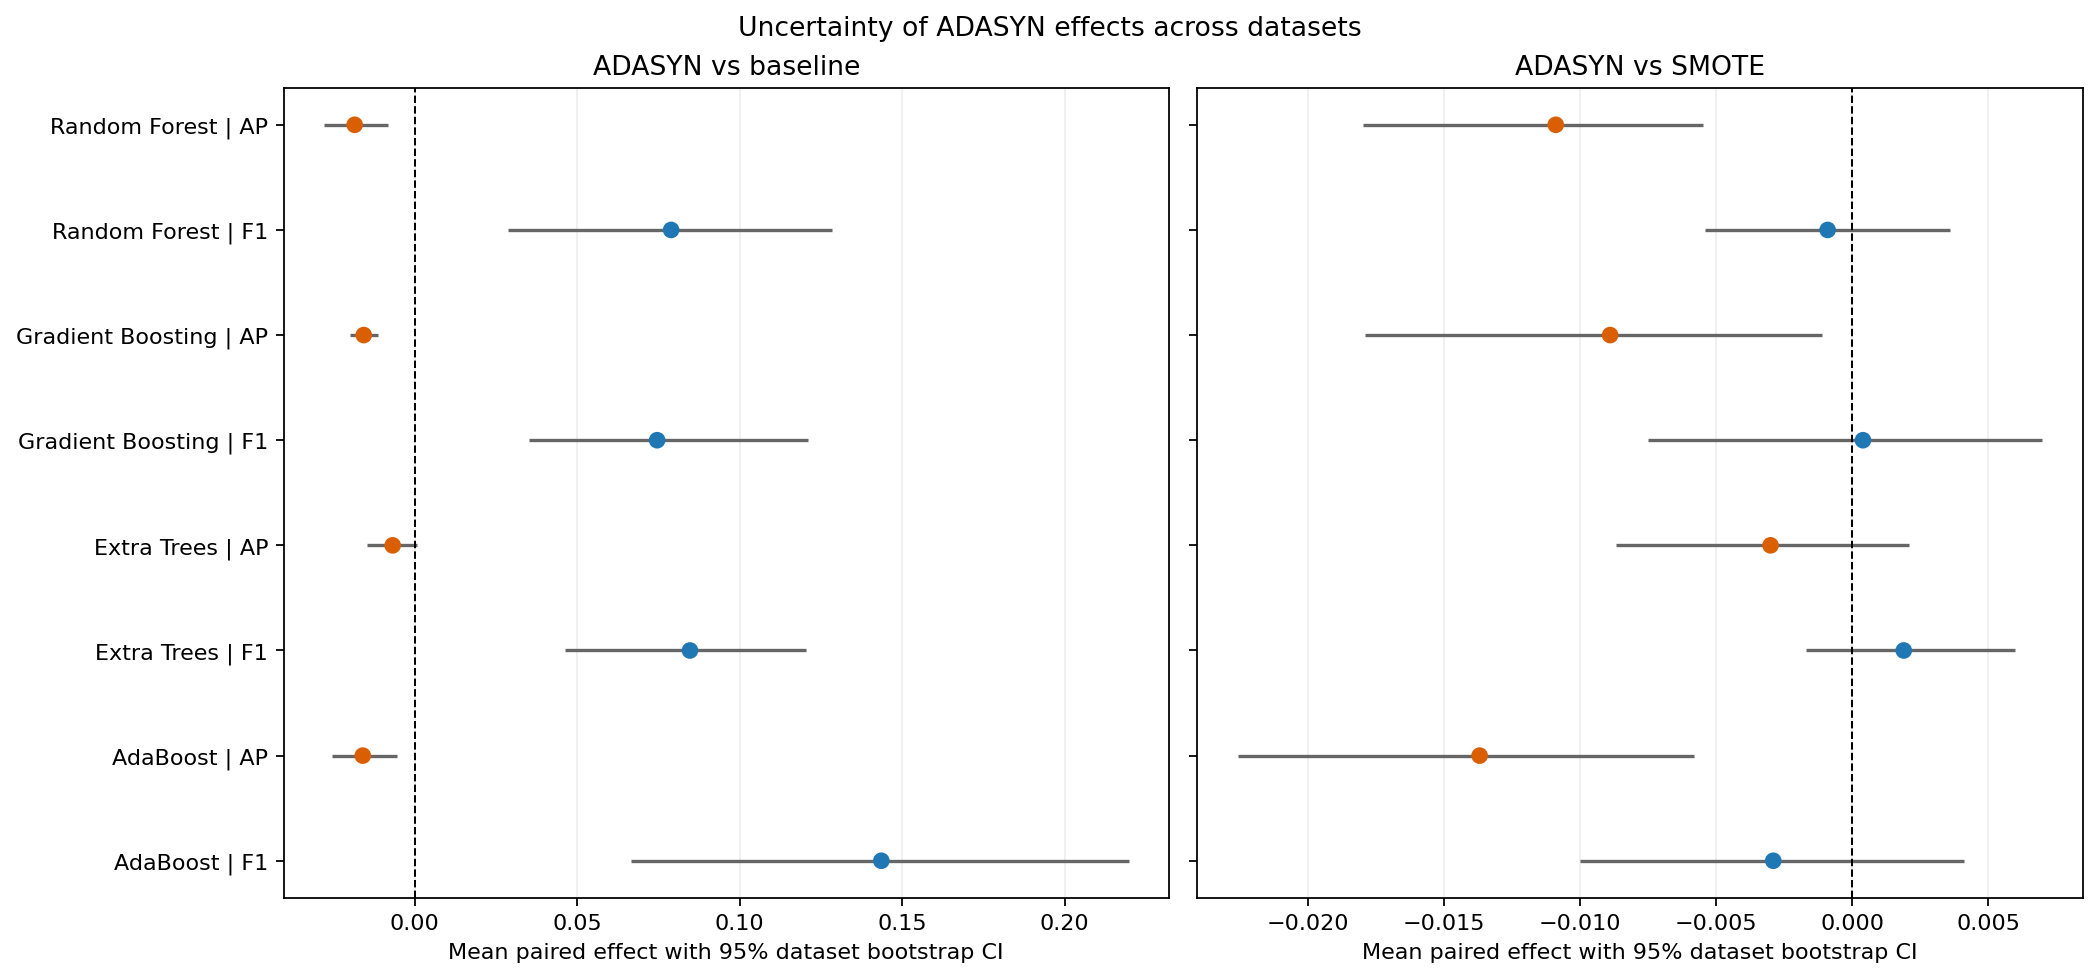

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True, constrained_layout=True)
for ax, comparison in zip(axes, PRIMARY_COMPARISONS):
    current = uncertainty_by_model.loc[
        uncertainty_by_model["Comparison"] == comparison
    ].reset_index(drop=True)
    positions = np.arange(len(current))
    means = current["Mean"].to_numpy()
    # Draw interval endpoints directly; percentile intervals need not contain the mean.
    ax.hlines(positions, current["CI_lo"], current["CI_hi"], color="#666666")
    colors = ["#1f77b4" if metric == "F1" else "#d95f02" for metric in current["Metric"]]
    ax.scatter(means, positions, c=colors, s=42, zorder=3)
    ax.axvline(0, color="black", linewidth=0.9, linestyle="--")
    ax.set_yticks(positions, current["Model"] + " | " + current["Metric"])
    ax.set(xlabel="Mean paired effect with 95% dataset bootstrap CI", title=comparison)
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("Uncertainty of ADASYN effects across datasets")
plt.show()